# 02 · Basic EDA

## Objective
Perform an **initial inspection** of the raw data: structure, types, missing values, duplicates,
unique values, summary statistics and the target distribution. No cleaning happens here — we only
**record** data-quality issues so they can be fixed in notebook 03.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use src/churn_utils.py
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.churn_utils import CHURN_PALETTE, RAW_DATA_PATH, set_plot_style

set_plot_style()
pd.set_option("display.max_columns", None)

df = pd.read_csv(RAW_DATA_PATH)

## 1. Shape and column names

In [2]:
print("Rows, columns:", df.shape)
print(list(df.columns))

Rows, columns: (7043, 21)
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


## 2. Data types

In [3]:
df.dtypes.value_counts()

str        18
int64       2
float64     1
Name: count, dtype: int64

In [4]:
df.dtypes.to_frame("dtype").T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,str,str


**Observations**
- 18 text columns, 2 integer (`SeniorCitizen`, `tenure`), 1 float (`MonthlyCharges`).
- `TotalCharges` is text (`str`) but represents money → **incorrect data type**.
- `SeniorCitizen` is stored as 0/1 while the other binary flags use Yes/No → **inconsistent encoding**.

## 3. Missing values

`isna()` only detects real nulls. A numeric column stored as text may hide missing values as
empty strings, so we check for **blank strings** too.

In [5]:
missing = pd.DataFrame({
    "null_values": df.isna().sum(),
    "blank_strings": df.apply(lambda col: col.astype(str).str.strip().eq("").sum()),
})
missing[missing.sum(axis=1) > 0]

,null_values,blank_strings
TotalCharges,0,11


**Observations**
- No real nulls, but `TotalCharges` contains **11 blank strings** — these are hidden missing values
  and explain why pandas read the column as text.

## 4. Duplicate records

In [6]:
print("Fully duplicated rows:          ", df.duplicated().sum())
print("Duplicated customerID values:   ", df["customerID"].duplicated().sum())
print("Duplicates ignoring customerID: ", df.drop(columns="customerID").duplicated().sum())

Fully duplicated rows:           0
Duplicated customerID values:    0
Duplicates ignoring customerID:  22


**Observations**
- No duplicated rows and every `customerID` is unique.
- 22 rows share an identical profile with another customer when the ID is ignored. With only ~20
  categorical columns and common plan combinations, identical profiles of *different* customers are
  plausible, so these are not treated as data-entry duplicates.

## 5. Unique values per column

In [7]:
df.nunique().sort_values().to_frame("n_unique").T

,Churn,gender,SeniorCitizen,Partner,Dependents,PaperlessBilling,PhoneService,Contract,StreamingMovies,StreamingTV,TechSupport,OnlineBackup,OnlineSecurity,InternetService,MultipleLines,DeviceProtection,PaymentMethod,tenure,MonthlyCharges,TotalCharges,customerID
n_unique,2,2,2,2,2,2,2,3,3,3,3,3,3,3,3,3,4,73,1585,6531,7043


## 6. Summary statistics

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [9]:
df.describe(include="str").T

,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


**Observations**
- `tenure`: mean ≈ 32 months, median 29, range 0–72 (72 looks like a cap in the data).
- `MonthlyCharges`: median 70.35 is above the mean 64.76 → a cluster of low-priced plans pulls the mean down.
- `SeniorCitizen`: only ~16% of customers are seniors.
- Most customers are on **month-to-month** contracts (3,875 of 7,043) and **electronic check** is the most
  common payment method.
- `TotalCharges` statistics can't be computed yet because of its text type.

## 7. Target variable distribution

,count,share
Churn,,
No,5174,0.735
Yes,1869,0.265


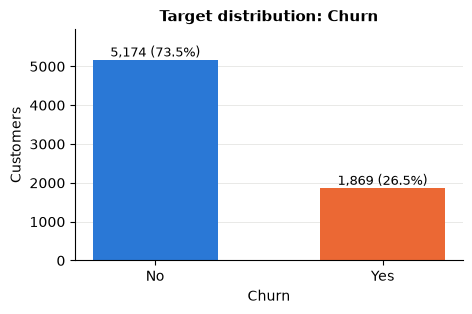

In [10]:
churn_summary = pd.DataFrame({
    "count": df["Churn"].value_counts(),
    "share": df["Churn"].value_counts(normalize=True).round(3),
})
display(churn_summary)

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(churn_summary.index, churn_summary["count"],
       color=[CHURN_PALETTE[c] for c in churn_summary.index], width=0.55)
for i, (count, share) in enumerate(zip(churn_summary["count"], churn_summary["share"])):
    ax.text(i, count + 80, f"{count:,} ({share:.1%})", ha="center", fontsize=9)
ax.set(title="Target distribution: Churn", xlabel="Churn", ylabel="Customers")
ax.set_ylim(0, churn_summary["count"].max() * 1.15)
plt.show()

**Observations**
- 73.5% No vs 26.5% Yes. A model that always predicts "No" would already be ~73.5% accurate, so
  **accuracy is not a useful headline metric** here.
- The imbalance is moderate (not extreme), so heavy resampling is probably unnecessary; this is
  revisited in notebook 05.

## Conclusion — data-quality issues to fix in notebook 03

| Issue | Column | Evidence |
|---|---|---|
| Wrong data type | `TotalCharges` | stored as text |
| Hidden missing values | `TotalCharges` | 11 blank strings |
| Inconsistent encoding | `SeniorCitizen` | 0/1 instead of Yes/No |
| Identifier column | `customerID` | 7,043 unique values, no predictive meaning |

No duplicate customers and no other missing values were found. The target is moderately imbalanced (26.5% churn).